# Exponential from uniform

Lecture 2 (16/11) - Distributions

## Exercise

1. Generate $10^6$ values of variable $t$, uniformly distributed in $[0, \Delta t = 10^3]$.
2. Sort the list of generated values.
3. Compute the interval $\Delta t_i = t_i - t_{i-1}$ between subsequent events.
4. Plot the distribution of $\Delta t_i$ (or a histogram).
5. Fit it with an exponential. Does it work? Do you get back the input parameters?

## Solution

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import uniform
from scipy.stats import expon

from scipy.optimize import curve_fit

### Functions

In [2]:
def uniform(a, b, size, rng):
    """Uniform in [a, b): rescale a uniform in [0, 1)."""
    return a + (b - a) * rng.random(size)

def exp_pdf(t, A, lam):
    return A * np.exp(-lam * t)

### Plots

In [3]:
# Data
N, T = 10**6, 1e3
rng = np.random.default_rng(12345)       # fixed seed, reproducible


In [14]:
# Samples my uniform
t_mine = uniform(0, T, N, rng)

# Sort and take the differences
dt_mine = np.diff(np.sort(t_mine))

# Histograms with the same bins
bins = np.linspace(0, 8e-3, 101)
x = 0.5 * (bins[1:] + bins[:-1])
c_mine, _ = np.histogram(dt_mine, bins=bins, density="true")


In [15]:
lam = N / T                      # rate: mean number of points per unit time
expected = lam * np.exp(-lam * x)   # expected counts per bin

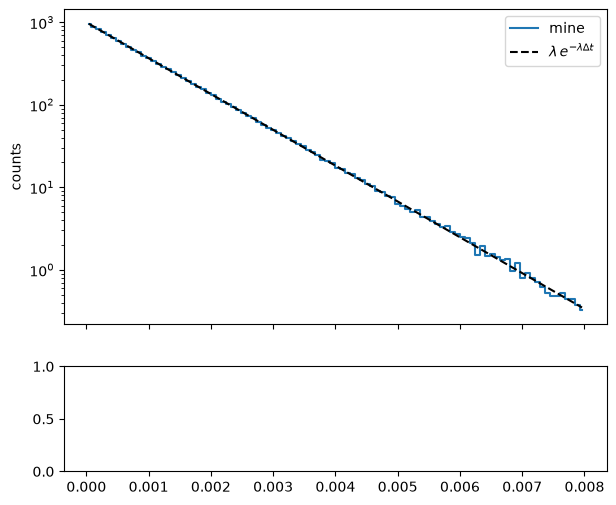

In [16]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})
ax.step(x, c_mine, where="mid", label="mine")
ax.plot(x, expected, "k--", label=r"$\lambda\,e^{-\lambda \Delta t}$")
ax.set_yscale("log")
ax.set_ylabel("counts")
ax.legend()
plt.show()